# SPOTIFY INSIGHTS — Beyond the Streams
### Exploratory Data Analysis | Music Streaming Trends

**Dataset:** Most Streamed Spotify Songs 2024  
**Purpose:** Explore track performance, streaming platforms, artist reach, popularity and engagement.

> Run the notebook from the project root or keep the notebook inside `notebooks/`. The loader below checks both likely CSV locations.


## Dataset Introduction

The dataset used in this project is **Most Streamed Spotify Songs 2024**. It contains information about popular music tracks and their performance on different digital music platforms.

Each row represents a track record. The dataset includes information about song names, artists, release dates, Spotify streams, playlist reach, YouTube views, TikTok engagement and other music statistics.

The purpose of this analysis is to understand music popularity, compare streaming platforms and discover relationships between different music performance metrics.

**Dataset Source:** Kaggle  
**Original Dataset Size:** 4,600 rows and 29 columns  
**Cleaned Dataset Size:** 4,593 rows and 30 columns

> Add the exact Kaggle dataset URL you originally used here.



## Dataset Column Guide

The following table explains the important columns used in this analysis.

| Column Name | Description |
|---|---|
| Track | Name of the song |
| Album Name | Name of the album |
| Artist | Name of the singer or artist |
| Release Date | Date when the song was released |
| Track Score | Popularity score of the track |
| Spotify Streams | Total Spotify streams |
| Spotify Playlist Count | Number of Spotify playlists containing the track |
| Spotify Playlist Reach | Estimated audience reached through Spotify playlists |
| Spotify Popularity | Spotify popularity score |
| YouTube Views | Total YouTube views |
| YouTube Likes | Total YouTube likes |
| TikTok Posts | Number of TikTok posts using the track |
| TikTok Likes | Likes received on TikTok |
| TikTok Views | Total TikTok views |
| Explicit Track | Indicates whether a track contains explicit content (1 = Yes, 0 = No) |
| Release Year | Year of release, created during data preparation |
| Release Month | Month of release, created during data preparation |

These columns help us understand song popularity, streaming performance and audience engagement across different platforms.


## 1. Import libraries and load the dataset

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from IPython.display import display

sns.set_theme(style="darkgrid", palette="viridis")
plt.rcParams["figure.figsize"] = (11, 6)

possible_paths = ["data/spotify.csv", "../data/spotify.csv"]
DATA_PATH = next((p for p in possible_paths if os.path.exists(p)), None)

if DATA_PATH is None:
    raise FileNotFoundError("Could not find data/spotify.csv. Place the CSV in the project's data folder.")

df_raw = pd.read_csv(DATA_PATH, encoding="latin1", engine="python")
print("Dataset loaded successfully!")
print("Original shape:", df_raw.shape)
display(df_raw.head())

Dataset loaded successfully!
Original shape: (4600, 29)


,Track,Album Name,Artist,Release Date,ISRC,All Time Rank,Track Score,Spotify Streams,Spotify Playlist Count,Spotify Playlist Reach,...,SiriusXM Spins,Deezer Playlist Count,Deezer Playlist Reach,Amazon Playlist Count,Pandora Streams,Pandora Track Stations,Soundcloud Streams,Shazam Counts,TIDAL Popularity,Explicit Track
0,MILLION DOLLAR BABY,Million Dollar Baby - Single,Tommy Richman,4/26/2024,QM24S2402528,1,725.4,"390,470,936","30,716","196,631,588",...,684,62.0,"17,598,718",114.0,"18,004,655","22,931","4,818,457","2,669,262",NaN,0
1,Not Like Us,Not Like Us,Kendrick Lamar,5/4/2024,USUG12400910,2,545.9,"323,703,884","28,113","174,597,137",...,3,67.0,"10,422,430",111.0,"7,780,028","28,444","6,623,075","1,118,279",NaN,1
2,i like the way you kiss me,I like the way you kiss me,Artemas,3/19/2024,QZJ842400387,3,538.4,"601,309,283","54,331","211,607,669",...,536,136.0,"36,321,847",172.0,"5,022,621","5,639","7,208,651","5,285,340",NaN,0
3,Flowers,Flowers - Single,Miley Cyrus,1/12/2023,USSM12209777,4,444.9,"2,031,280,633","269,802","136,569,078",...,"2,182",264.0,"24,684,248",210.0,"190,260,277","203,384",NaN,"11,822,942",NaN,0
4,Houdini,Houdini,Eminem,5/31/2024,USUG12403398,5,423.3,"107,034,922","7,223","151,469,874",...,1,82.0,"17,660,624",105.0,"4,493,884","7,006","207,179","457,017",NaN,1


## 2. Understand the dataset

In [2]:
print("Rows:", df_raw.shape[0])
print("Columns:", df_raw.shape[1])
print("\nColumn names:")
print(df_raw.columns.tolist())
print("\nData types:")
display(df_raw.dtypes.to_frame("Data Type"))
print("\nDataset information:")
df_raw.info()

Rows: 4600
Columns: 29

Column names:
['Track', 'Album Name', 'Artist', 'Release Date', 'ISRC', 'All Time Rank', 'Track Score', 'Spotify Streams', 'Spotify Playlist Count', 'Spotify Playlist Reach', 'Spotify Popularity', 'YouTube Views', 'YouTube Likes', 'TikTok Posts', 'TikTok Likes', 'TikTok Views', 'YouTube Playlist Reach', 'Apple Music Playlist Count', 'AirPlay Spins', 'SiriusXM Spins', 'Deezer Playlist Count', 'Deezer Playlist Reach', 'Amazon Playlist Count', 'Pandora Streams', 'Pandora Track Stations', 'Soundcloud Streams', 'Shazam Counts', 'TIDAL Popularity', 'Explicit Track']

Data types:


,Data Type
Track,str
Album Name,str
Artist,str
Release Date,str
ISRC,str
All Time Rank,str
Track Score,float64
Spotify Streams,str
Spotify Playlist Count,str
Spotify Playlist Reach,str



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Track                       4600 non-null   str    
 1   Album Name                  4600 non-null   str    
 2   Artist                      4595 non-null   str    
 3   Release Date                4600 non-null   str    
 4   ISRC                        4600 non-null   str    
 5   All Time Rank               4600 non-null   str    
 6   Track Score                 4600 non-null   float64
 7   Spotify Streams             4487 non-null   str    
 8   Spotify Playlist Count      4530 non-null   str    
 9   Spotify Playlist Reach      4528 non-null   str    
 10  Spotify Popularity          3796 non-null   float64
 11  YouTube Views               4292 non-null   str    
 12  YouTube Likes               4285 non-null   str    
 13  TikTok Posts          

In [3]:
print("Descriptive statistics — numeric columns:")
display(df_raw.describe(include="number").T)
print("\nDescriptive statistics — all columns:")
display(df_raw.describe(include="all").T)

Descriptive statistics — numeric columns:


,count,mean,std,min,25%,50%,75%,max
Track Score,4600.0,41.844043,38.543766,19.4,23.3,29.9,44.425,725.4
Spotify Popularity,3796.0,63.501581,16.186438,1.0,61.0,67.0,73.000,96.0
Apple Music Playlist Count,4039.0,54.603120,71.612270,1.0,10.0,28.0,70.000,859.0
Deezer Playlist Count,3679.0,32.310954,54.274538,1.0,5.0,15.0,37.000,632.0
Amazon Playlist Count,3545.0,25.348942,25.989826,1.0,8.0,17.0,34.000,210.0
TIDAL Popularity,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Explicit Track,4600.0,0.358913,0.479734,0.0,0.0,0.0,1.000,1.0



Descriptive statistics — all columns:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Track,4600,4370,Danza Kuduro - Cover,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Album Name,4600,4005,Un Verano Sin Ti,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Artist,4595,1999,Taylor Swift,63,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Release Date,4600,1562,1/1/2012,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ISRC,4600,4598,TCAGJ2289254,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
All Time Rank,4600,4577,355,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Track Score,4600.0,NaN,NaN,NaN,41.844043,38.543766,19.4,23.3,29.9,44.425,725.4
Spotify Streams,4487,4425,"1,655,575,417",4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Spotify Playlist Count,4530,4207,1,46,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Spotify Playlist Reach,4528,4478,3,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Data quality assessment

In [4]:
quality = pd.DataFrame({
    "Missing Values": df_raw.isna().sum(),
    "Missing %": (df_raw.isna().mean() * 100).round(2),
    "Unique Values": df_raw.nunique(dropna=True),
    "Data Type": df_raw.dtypes.astype(str)
}).sort_values("Missing %", ascending=False)

display(quality)
print("Duplicate rows:", df_raw.duplicated().sum())

,Missing Values,Missing %,Unique Values,Data Type
TIDAL Popularity,4600,100.00,0,float64
Soundcloud Streams,3333,72.46,1265,str
SiriusXM Spins,2123,46.15,689,str
Pandora Track Stations,1268,27.57,2975,str
TikTok Posts,1173,25.50,3318,str
Pandora Streams,1106,24.04,3491,str
Amazon Playlist Count,1055,22.93,147,float64
YouTube Playlist Reach,1009,21.93,3458,str
TikTok Views,981,21.33,3616,str
TikTok Likes,980,21.30,3615,str


Duplicate rows: 2


## 4. Data cleaning and preparation

In [5]:

# Create a copy of the original dataset
df = df_raw.copy()

# 1. Remove duplicate records
before = len(df)
df = df.drop_duplicates()
print("Duplicate rows removed:", before - len(df))

# 2. Remove completely empty columns
empty_columns = df.columns[df.isna().all()].tolist()
df = df.drop(columns=empty_columns)
print("Completely empty columns removed:", empty_columns)

# 3. Remove rows without an Artist name
before = len(df)
df = df.dropna(subset=["Artist"])
print("Rows removed due to missing Artist:", before - len(df))

# 4. Convert numeric columns stored as text
numeric_candidates = [
    "All Time Rank", "Track Score", "Spotify Streams",
    "Spotify Playlist Count", "Spotify Playlist Reach",
    "Spotify Popularity", "YouTube Views", "YouTube Likes",
    "TikTok Posts", "TikTok Likes", "TikTok Views",
    "YouTube Playlist Reach", "Apple Music Playlist Count",
    "AirPlay Spins", "SiriusXM Spins", "Deezer Playlist Count",
    "Deezer Playlist Reach", "Amazon Playlist Count",
    "Pandora Streams", "Pandora Track Stations",
    "Soundcloud Streams", "Shazam Counts", "Explicit Track"
]

for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col].astype("string").str.replace(",", "", regex=False).str.strip(),
            errors="coerce"
        )

# 5. Convert Release Date into datetime
df["Release Date"] = pd.to_datetime(
    df["Release Date"], errors="coerce"
)

df["Release Year"] = df["Release Date"].dt.year
df["Release Month"] = df["Release Date"].dt.month_name()

# 6. Keep remaining missing platform measurements as NaN.
# We do not fill them with artificial median values.

print("\nDATA CLEANING SUMMARY")
print("Original shape:", df_raw.shape)
print("Cleaned shape:", df.shape)
print("Remaining missing values:", df.isna().sum().sum())
print("Remaining duplicate rows:", df.duplicated().sum())

display(df.head())



Duplicate rows removed: 2
Completely empty columns removed: ['TIDAL Popularity']
Rows removed due to missing Artist: 5

DATA CLEANING SUMMARY
Original shape: (4600, 29)
Cleaned shape: (4593, 30)
Remaining missing values: 18098
Remaining duplicate rows: 0


,Track,Album Name,Artist,Release Date,ISRC,All Time Rank,Track Score,Spotify Streams,Spotify Playlist Count,Spotify Playlist Reach,...,Deezer Playlist Count,Deezer Playlist Reach,Amazon Playlist Count,Pandora Streams,Pandora Track Stations,Soundcloud Streams,Shazam Counts,Explicit Track,Release Year,Release Month
0,MILLION DOLLAR BABY,Million Dollar Baby - Single,Tommy Richman,2024-04-26,QM24S2402528,1,725.4,390470936,30716,196631588,...,62.0,17598718,114.0,18004655,22931,4818457,2669262,0,2024,April
1,Not Like Us,Not Like Us,Kendrick Lamar,2024-05-04,USUG12400910,2,545.9,323703884,28113,174597137,...,67.0,10422430,111.0,7780028,28444,6623075,1118279,1,2024,May
2,i like the way you kiss me,I like the way you kiss me,Artemas,2024-03-19,QZJ842400387,3,538.4,601309283,54331,211607669,...,136.0,36321847,172.0,5022621,5639,7208651,5285340,0,2024,March
3,Flowers,Flowers - Single,Miley Cyrus,2023-01-12,USSM12209777,4,444.9,2031280633,269802,136569078,...,264.0,24684248,210.0,190260277,203384,<NA>,11822942,0,2023,January
4,Houdini,Houdini,Eminem,2024-05-31,USUG12403398,5,423.3,107034922,7223,151469874,...,82.0,17660624,105.0,4493884,7006,207179,457017,1,2024,May


In [6]:
print("Data types after cleaning:")
display(df.dtypes.to_frame("Cleaned Data Type"))
print("\nMissing values after cleaning:")
display(df.isna().sum().to_frame("Missing Values"))
print("\nDuplicate rows after cleaning:", df.duplicated().sum())

Data types after cleaning:


,Cleaned Data Type
Track,str
Album Name,str
Artist,str
Release Date,datetime64[us]
ISRC,str
All Time Rank,Int64
Track Score,Float64
Spotify Streams,Int64
Spotify Playlist Count,Int64
Spotify Playlist Reach,Int64



Missing values after cleaning:


,Missing Values
Track,0
Album Name,0
Artist,0
Release Date,0
ISRC,0
All Time Rank,0
Track Score,0
Spotify Streams,108
Spotify Playlist Count,65
Spotify Playlist Reach,67



Duplicate rows after cleaning: 0


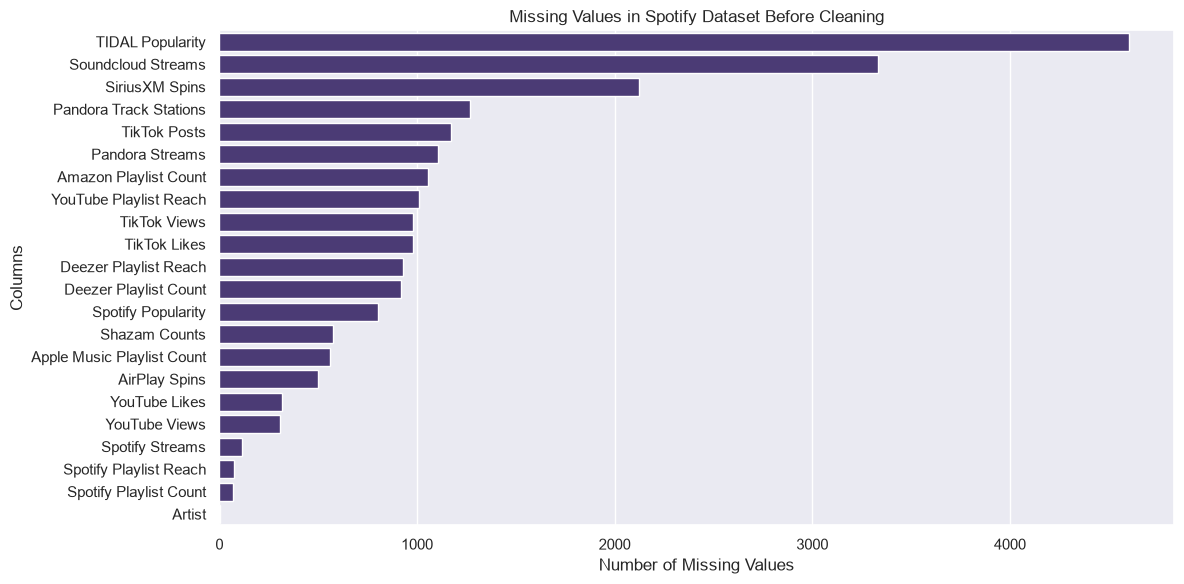

In [12]:

# Missing Values Visualization (Before Cleaning)

missing_before = df_raw.isnull().sum()
missing_before = missing_before[missing_before > 0].sort_values(ascending=False)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=missing_before.values,
    y=missing_before.index
)

plt.title("Missing Values in Spotify Dataset Before Cleaning")
plt.xlabel("Number of Missing Values")
plt.ylabel("Columns")
plt.tight_layout()
plt.show()


**Observation:**

The dataset contained missing values in several music streaming platform columns. TIDAL Popularity was completely empty, while other columns had partial missing values. The completely empty column was removed, and the remaining missing measurements were preserved to avoid introducing inaccurate data.



Column: Track Score
Q1: 23.3
Q3: 44.4
IQR: 21.099999999999998
Lower Limit: -8.349999999999998
Upper Limit: 76.05
Number of Outliers: 405


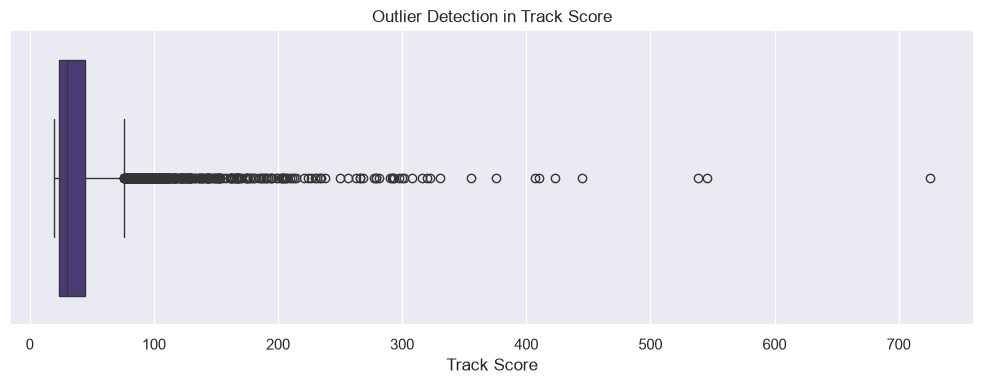


Column: Spotify Streams
Q1: 70354552
Q3: 629102459
IQR: 558747907
Lower Limit: -767767308.5
Upper Limit: 1467224319.5
Number of Outliers: 289


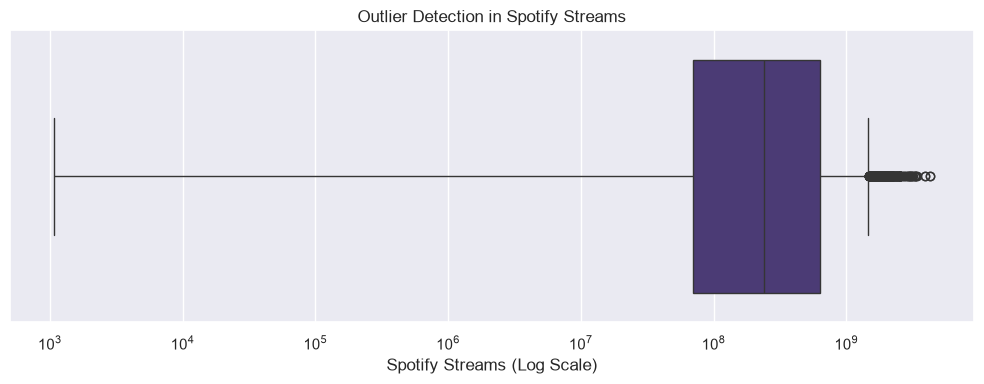

In [14]:

# Outlier Analysis using IQR Method

outlier_columns = ["Track Score", "Spotify Streams"]

for col in outlier_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print("\nColumn:", col)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Number of Outliers:", len(outliers))

    plt.figure(figsize=(10, 4))

    if col == "Spotify Streams":
        plot_data = df[col].dropna()
        plot_data = plot_data[plot_data > 0]

        sns.boxplot(x=plot_data)
        plt.xscale("log")
        plt.xlabel("Spotify Streams (Log Scale)")
    else:
        sns.boxplot(x=df[col].dropna())
        plt.xlabel(col)

    plt.title(f"Outlier Detection in {col}")
    plt.tight_layout()
    plt.show()



### Outlier Analysis and Decision

The IQR method was used to identify outliers in Track Score and Spotify Streams. Box plots were created to visualize unusually high and low values.

**Decision:** The outliers were kept because extremely popular songs can naturally have very high streaming counts and track scores. Removing these genuine values could hide important music trends.


## 5. Outlier detection using the IQR method

In [7]:
def iqr_outlier_summary(data, columns):
    rows = []
    for col in columns:
        series = data[col].dropna()
        if series.empty:
            continue
        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        count = int(((series < lower) | (series > upper)).sum())
        rows.append({
            "Column": col, "Q1": q1, "Q3": q3,
            "IQR": iqr, "Lower Bound": lower,
            "Upper Bound": upper, "Outlier Count": count
        })
    return pd.DataFrame(rows).sort_values("Outlier Count", ascending=False)

outlier_candidates = [
    c for c in ["Track Score", "Spotify Streams", "YouTube Views",
                "TikTok Views", "Spotify Playlist Reach", "Shazam Counts"]
    if c in df.columns
]
outlier_report = iqr_outlier_summary(df, outlier_candidates)
display(outlier_report)

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
5,Shazam Counts,230094.00,2686409.0,2.456315e+06,-3.454378e+06,6.370882e+06,437
2,YouTube Views,40756124.25,464692085.0,4.239360e+08,-5.951478e+08,1.100596e+09,422
3,TikTok Views,58980168.00,914597307.0,8.556171e+08,-1.224446e+09,2.198023e+09,409
0,Track Score,23.30,44.4,2.110000e+01,-8.350000e+00,7.605000e+01,405
4,Spotify Playlist Reach,4789848.50,29668021.5,2.487817e+07,-3.252741e+07,6.698528e+07,374
1,Spotify Streams,70354552.00,629102459.0,5.587479e+08,-7.677673e+08,1.467224e+09,289


## 6. Univariate analysis

In [8]:
# Distribution of track scores
if "Track Score" in df.columns:
    fig = px.histogram(df, x="Track Score", nbins=35,
                       title="Distribution of Track Scores",
                       color_discrete_sequence=["#1ED760"])
    fig.show()

# Explicit vs non-explicit tracks
if "Explicit Track" in df.columns:
    explicit_counts = df["Explicit Track"].map({0: "Non-explicit", 1: "Explicit"}).fillna("Unknown").value_counts().reset_index()
    explicit_counts.columns = ["Track Type", "Count"]
    fig = px.pie(explicit_counts, names="Track Type", values="Count",
                 title="Explicit vs Non-explicit Tracks", hole=0.55)
    fig.show()

# Top artists by number of tracks in this dataset
if "Artist" in df.columns:
    top_artists = df["Artist"].value_counts().head(10).reset_index()
    top_artists.columns = ["Artist", "Track Count"]
    fig = px.bar(top_artists.sort_values("Track Count"),
                 x="Track Count", y="Artist", orientation="h",
                 title="Top 10 Artists by Track Count",
                 color="Track Count", color_continuous_scale="Viridis")
    fig.show()

## 7. Bivariate and platform analysis

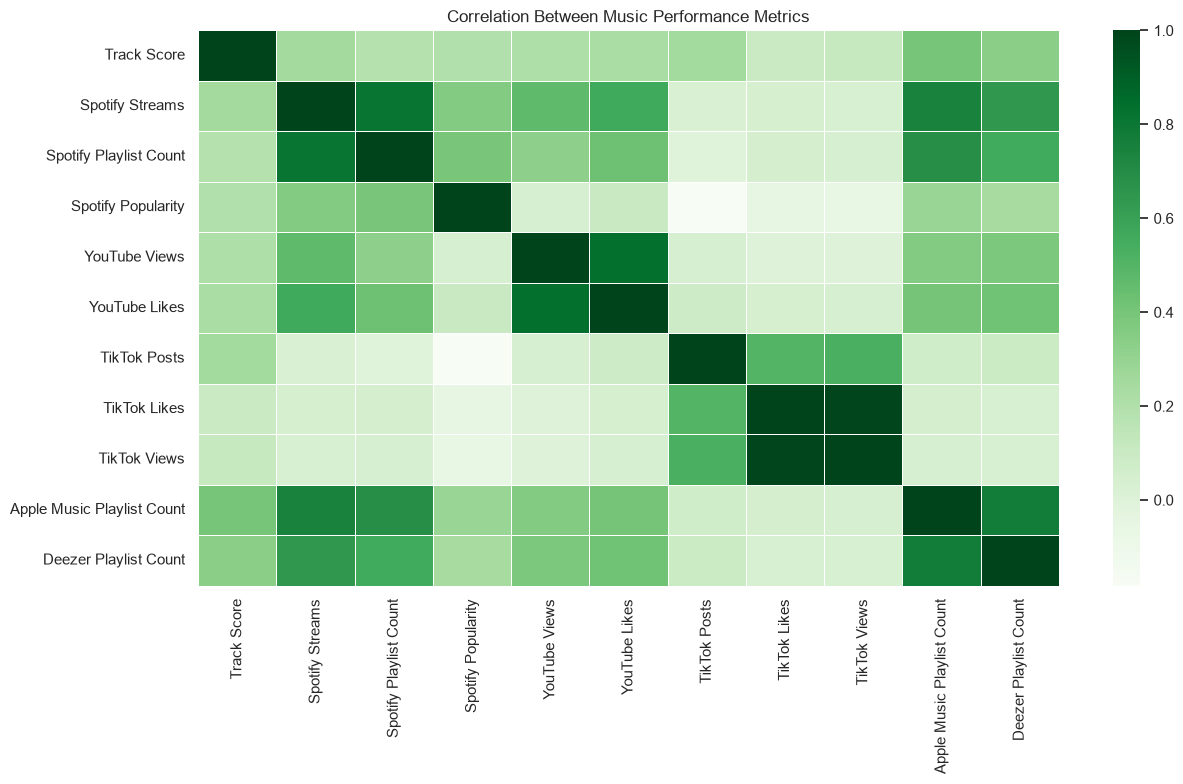

In [9]:
# Spotify streams vs track score
if {"Spotify Streams", "Track Score"}.issubset(df.columns):
    fig = px.scatter(df, x="Spotify Streams", y="Track Score",
                     hover_name="Track", color="Explicit Track" if "Explicit Track" in df.columns else None,
                     title="Spotify Streams vs Track Score",
                     opacity=0.65)
    fig.show()

# Spotify streams vs YouTube views
if {"Spotify Streams", "YouTube Views"}.issubset(df.columns):
    fig = px.scatter(df, x="Spotify Streams", y="YouTube Views",
                     hover_name="Track", title="Spotify Streams vs YouTube Views",
                     opacity=0.6)
    fig.show()

# Correlation heatmap
corr_cols = [c for c in [
    "Track Score", "Spotify Streams", "Spotify Playlist Count",
    "Spotify Popularity", "YouTube Views", "YouTube Likes",
    "TikTok Posts", "TikTok Likes", "TikTok Views",
    "Apple Music Playlist Count", "Deezer Playlist Count"
] if c in df.columns]
if len(corr_cols) >= 2:
    plt.figure(figsize=(13, 8))
    sns.heatmap(df[corr_cols].corr(), cmap="Greens", annot=False, linewidths=0.4)
    plt.title("Correlation Between Music Performance Metrics")
    plt.tight_layout()
    plt.show()

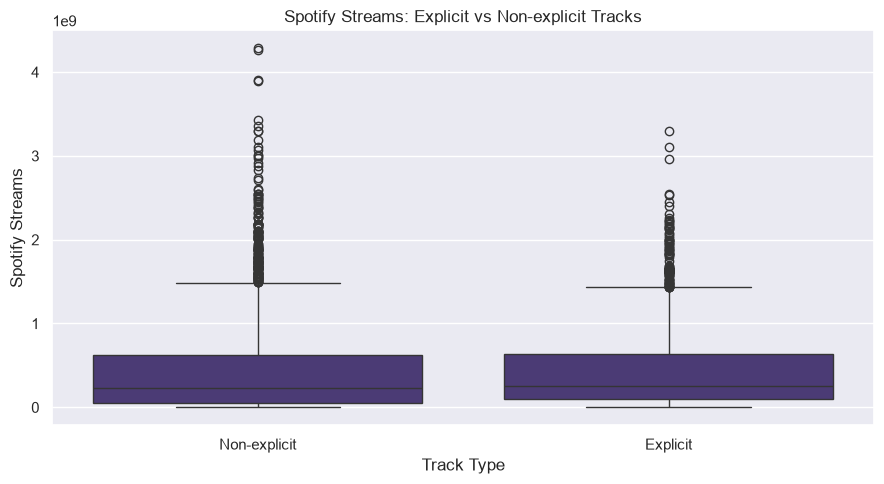

,mean,median,count
Track Type,,,
Explicit,445349873.47,254017030.0,1642
Non-explicit,448594901.84,225556005.0,2843


In [16]:

# Comparing Spotify Streams by Track Type

comparison_data = df.dropna(
    subset=["Spotify Streams", "Explicit Track"]
).copy()

comparison_data["Track Type"] = comparison_data[
    "Explicit Track"
].map({
    0: "Non-explicit",
    1: "Explicit"
})

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=comparison_data,
    x="Track Type",
    y="Spotify Streams"
)

plt.title("Spotify Streams: Explicit vs Non-explicit Tracks")
plt.xlabel("Track Type")
plt.ylabel("Spotify Streams")
plt.tight_layout()
plt.show()

# Compare average streams
display(
    comparison_data.groupby("Track Type")["Spotify Streams"]
    .agg(["mean", "median", "count"])
    .round(2)
)



**Observation:**

This comparison shows the distribution of Spotify streams for explicit and non-explicit tracks. The box plot helps identify differences in their streaming performance and median values.


## 8. Eight research questions

Use the results generated below to answer these questions in your own words:

1. Which tracks have the highest Spotify stream counts?
2. Which artists appear most frequently in the dataset?
3. Is a higher Spotify stream count associated with a higher Track Score?
4. How do Spotify streams compare with YouTube views?
5. Which tracks have the highest YouTube engagement (likes)?
6. How does explicit content compare with non-explicit content in the dataset?
7. Which tracks have the greatest playlist reach on Spotify?
8. Which numeric music-performance metrics show the strongest correlations?

The code below calculates evidence for each question. Use the printed results and charts rather than guessing.

In [17]:

# STEP 8: Answering Eight Research Questions

# Q1: Top 10 tracks by Spotify Streams
q1 = df.nlargest(10, "Spotify Streams")

fig = px.bar(
    q1.sort_values("Spotify Streams"),
    x="Spotify Streams",
    y="Track",
    orientation="h",
    color="Spotify Streams",
    title="Q1: Top 10 Tracks by Spotify Streams",
    hover_data=["Artist"]
)
fig.show()


# Q2: Top 10 artists by number of tracks
q2 = df["Artist"].value_counts().head(10).reset_index()
q2.columns = ["Artist", "Track Count"]

fig = px.bar(
    q2.sort_values("Track Count"),
    x="Track Count",
    y="Artist",
    orientation="h",
    title="Q2: Artists with the Most Tracks",
    color="Track Count"
)
fig.show()


# Q3: Spotify Streams vs Track Score
fig = px.scatter(
    df,
    x="Spotify Streams",
    y="Track Score",
    title="Q3: Relationship Between Spotify Streams and Track Score",
    hover_name="Track",
    opacity=0.6
)
fig.show()


# Q4: Spotify Streams vs YouTube Views
fig = px.scatter(
    df.dropna(subset=["Spotify Streams", "YouTube Views"]),
    x="Spotify Streams",
    y="YouTube Views",
    title="Q4: Spotify Streams vs YouTube Views",
    hover_name="Track",
    opacity=0.6
)
fig.show()


# Q5: Top 10 tracks by YouTube Likes
q5 = df.nlargest(10, "YouTube Likes")

fig = px.bar(
    q5.sort_values("YouTube Likes"),
    x="YouTube Likes",
    y="Track",
    orientation="h",
    title="Q5: Top 10 Tracks by YouTube Likes",
    hover_data=["Artist"],
    color="YouTube Likes"
)
fig.show()


# Q6: Explicit vs Non-explicit tracks
q6 = df["Explicit Track"].map({
    0: "Non-explicit",
    1: "Explicit"
}).value_counts().reset_index()

q6.columns = ["Track Type", "Count"]

fig = px.pie(
    q6,
    names="Track Type",
    values="Count",
    title="Q6: Explicit vs Non-explicit Tracks",
    hole=0.5
)
fig.show()


# Q7: Top 10 tracks by Spotify Playlist Reach
q7 = df.nlargest(10, "Spotify Playlist Reach")

fig = px.bar(
    q7.sort_values("Spotify Playlist Reach"),
    x="Spotify Playlist Reach",
    y="Track",
    orientation="h",
    title="Q7: Top 10 Tracks by Spotify Playlist Reach",
    hover_data=["Artist"],
    color="Spotify Playlist Reach"
)
fig.show()


# Q8: Strongest relationships between music metrics
corr_matrix = df[corr_cols].corr()

corr_pairs = (
    corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )
    .stack()
    .sort_values(key=abs, ascending=False)
)

q8 = corr_pairs.head(10).reset_index()
q8.columns = ["Metric 1", "Metric 2", "Correlation"]

fig = px.bar(
    q8,
    x="Correlation",
    y="Metric 1",
    color="Correlation",
    hover_data=["Metric 2"],
    title="Q8: Strongest Relationships Between Music Metrics"
)
fig.show()



## Written Answers to the Eight Research Questions

### Q1. Which tracks have the highest Spotify stream counts?

Blinding Lights by The Weeknd has the highest Spotify streams, with approximately 4.28 billion streams. It is followed by another Blinding Lights record with approximately 4.26 billion streams.

### Q2. Which artists appear most frequently in the dataset?

Drake and Taylor Swift are the most frequently appearing artists, with 63 track records each. Bad Bunny follows with 60 track records.

### Q3. Is a higher Spotify stream count associated with a higher Track Score?

There is a weak positive relationship between Spotify Streams and Track Score, with a correlation of approximately 0.251. This means that higher streams are slightly associated with higher track scores, but the relationship is not strong.

### Q4. How do Spotify streams compare with YouTube views?

Spotify Streams and YouTube Views have a moderate positive correlation of approximately 0.469. This suggests that tracks with more Spotify streams often receive more YouTube views.

### Q5. Which tracks have the highest YouTube engagement (likes)?

Dynamite by BTS has the highest YouTube engagement in terms of likes, with approximately 62.31 million likes. Despacito by Luis Fonsi comes second.

### Q6. How does explicit content compare with non-explicit content in the dataset?

The dataset contains 2,942 non-explicit tracks and 1,651 explicit tracks. Non-explicit tracks are more common. Their median Spotify streams are approximately 225.56 million, while explicit tracks have a median of approximately 254.02 million.

### Q7. Which tracks have the greatest playlist reach on Spotify?

Espresso by Sabrina Carpenter has the highest Spotify Playlist Reach, with approximately 262.34 million. This shows its strong presence across Spotify playlists.

### Q8. Which numeric music-performance metrics show the strongest correlations?

TikTok Likes and TikTok Views have the strongest positive correlation, approximately 0.993. This indicates that tracks receiving more TikTok views generally also receive more likes.


## 9. Additional findings and final summary

In [15]:
print("FINAL DATASET SUMMARY")
print("=" * 50)
print(f"Rows after cleaning: {len(df):,}")
print(f"Columns after cleaning: {df.shape[1]:,}")
if "Spotify Streams" in df.columns:
    print(f"Median Spotify streams: {df['Spotify Streams'].median():,.0f}")
    print(f"Maximum Spotify streams: {df['Spotify Streams'].max():,.0f}")
if "Track Score" in df.columns:
    print(f"Average track score: {df['Track Score'].mean():.2f}")
if "Artist" in df.columns:
    print(f"Unique artists: {df['Artist'].nunique():,}")

print("\nTop streamed track:")
if {"Track", "Artist", "Spotify Streams"}.issubset(df.columns):
    print(df.loc[df["Spotify Streams"].idxmax(), ["Track", "Artist", "Spotify Streams"]])

print("\nCleaning steps performed:")
print("- Removed duplicate rows")
print("- Removed completely empty columns")
print("- Removed rows with missing Artist")
print("- Converted numeric text columns into numbers")
print("- Converted Release Date into datetime")
print("- Preserved remaining missing platform measurements")
print("- Kept genuine outliers for accurate analysis")

FINAL DATASET SUMMARY
Rows after cleaning: 4,593
Columns after cleaning: 30
Median Spotify streams: 239,850,720
Maximum Spotify streams: 4,281,468,720
Average track score: 41.84
Unique artists: 1,999

Top streamed track:
Track              Blinding Lights
Artist                  The Weeknd
Spotify Streams         4281468720
Name: 55, dtype: object

Cleaning steps performed:
- Removed duplicate rows
- Removed completely empty columns
- Removed rows with missing Artist
- Converted numeric text columns into numbers
- Converted Release Date into datetime
- Preserved remaining missing platform measurements
- Kept genuine outliers for accurate analysis



## Three Main Findings

### Finding 1: Spotify Streaming Success
Blinding Lights by The Weeknd is the most streamed track in the dataset, with approximately 4.28 billion Spotify streams.

### Finding 2: Social Media Engagement
TikTok Likes and TikTok Views have a very strong positive correlation of approximately 0.993.

### Finding 3: Artist Popularity
Drake and Taylor Swift have the highest number of track records in the dataset, with 63 each.

## Actionable Suggestion

Music artists and record companies should focus on promoting songs through social media platforms such as TikTok and YouTube, while also improving their Spotify playlist presence. These platforms can help increase audience engagement and music discovery.



## 10. Conclusion

This project explored popular Spotify songs using Python and different data analysis libraries. The analysis examined streaming performance, artist popularity, YouTube engagement, TikTok activity and playlist reach.

The results showed that Blinding Lights had the highest Spotify streams, Drake and Taylor Swift appeared most frequently, and TikTok Likes and TikTok Views had a very strong relationship.

Data cleaning helped improve the dataset by removing duplicate records, handling missing values, correcting data types and examining outliers.

Overall, this project helped us understand music trends and how different digital platforms contribute to music popularity.
